In [1]:
from IPython.display import Image, display

# Clustering
- Describing cellular structure by finding cell identities that relate to known cell states or cell cycle stages is called **cell identity annotation**.
- Structuring cells into clusters helps in identifying similar cells. Clusters are derived by minimizing the intra-cluster distance in the reduced expression space. Here, expression space determines the gene expression similarity of cells with respect to a dimensionality-reduced representation. The lower-dimensional representation is, for example, determined with PCA and the similarity scoring based on Euclidean distances.
- `KNN (K-Nearest-Neighbor)` graph consists of nodes reflecting cells in the dataset. It involves:
    - Calculation of Euclidean distance matrix on the PC-reduced expression space for all cells.
    - Connecting each cell to its K most similar cells.
    - K is set to values between 5 and 100, depending on the size of the dataset.
    - Dense regions in KNN-graph are detected by community detection methods like `Leiden` and `Louvain`.
- The `Leiden algorithm` is an improved version of the Louvain algorithm. It creates clusters by taking into account the number of links between cells in a cluster versus the overall expected number of links in the dataset. It involves:
    - Computing a clustering on a KNN graph.
    - The starting point is a singleton partition in which each node functions as its own community. The algorithm creates partitions by moving individual nodes from one community to another, which is refined afterwards to enhance the partitioning.
    - The refined partition is aggregated to a network. Subsequently, the algorithm moves again individual nodes in the aggregate network, until refinement no longer changes the partition.
    - All steps are repeated until the final clustering is created and partitions no longer change.
    - A higher resolution parameter leads to more clusters.
    - Allows efficient sub-clustering of particular clusters in the dataset by sub-setting the KNN graph. It enables identification of cell-type specific states within clusters or a finer cell type labeling. But, this can also lead to patterns that are noise in the data.

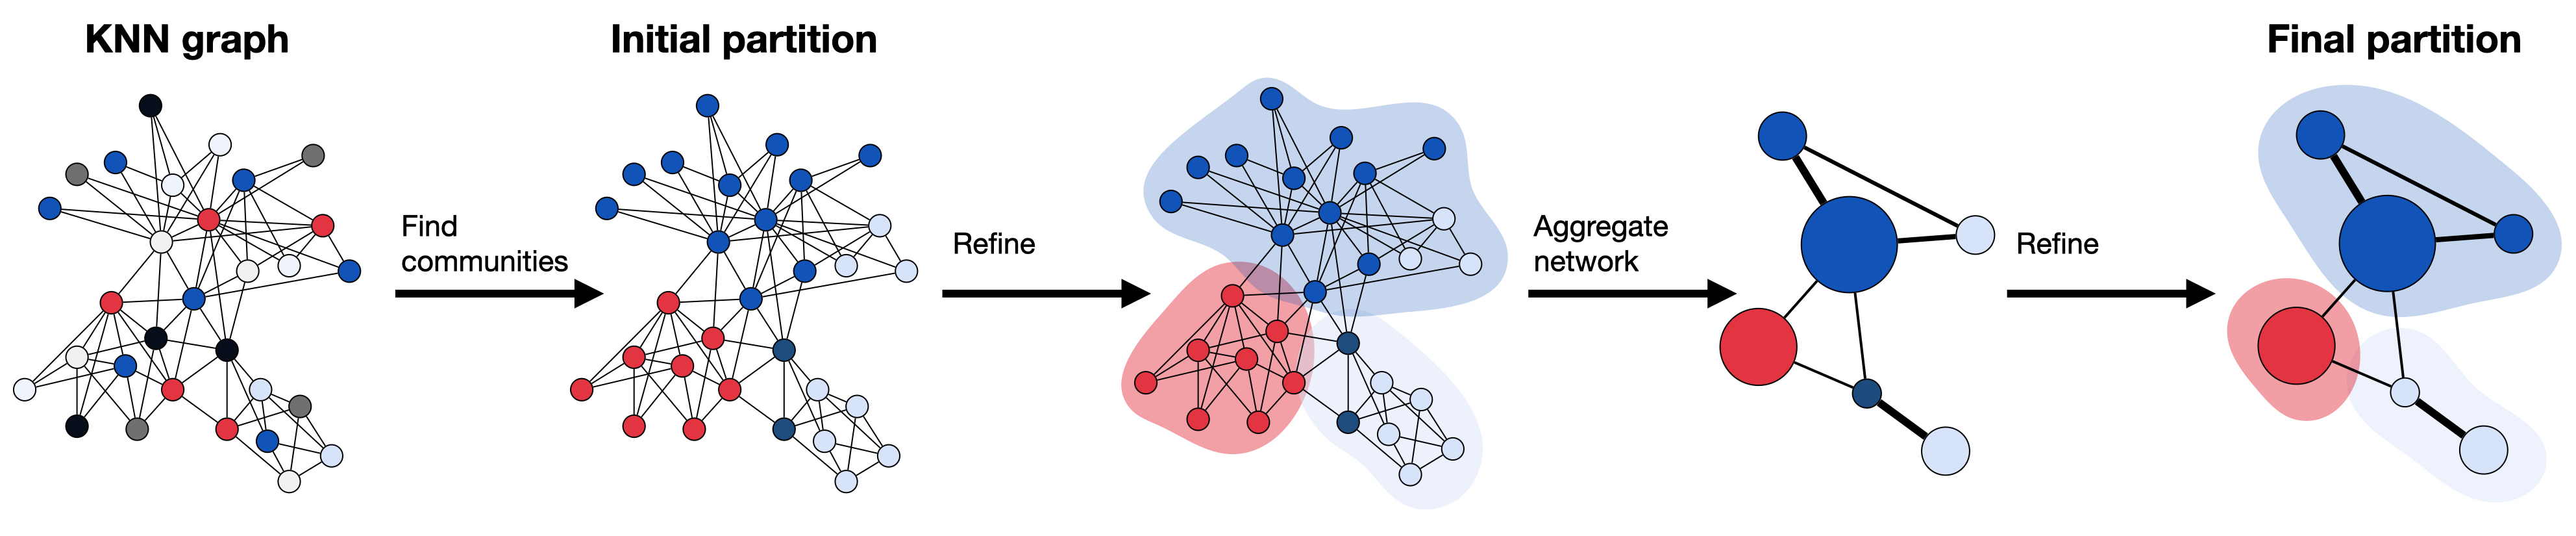

In [2]:
display(Image("../../images/leiden_clustering.jpeg"))

In [3]:
import lamindb as ln
import scanpy as sc

# Configure scanpy's settings for outfits and visualization
sc.settings.verbosity = 0
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

ln.connect("theislab/sc-best-practices")

→ connected lamindb: theislab/sc-best-practices
! connected in read-only mode, please use ln.DB("theislab/sc-best-practices") instead


# Clustering human bone marrow cells

This is the site4-donor8 after dimensionality reduction, normalized with scran.

In [4]:
af = ln.Artifact.get(
    key="preprocessing_visualization/s4d8_dimensionality_reduction.h5ad", is_latest=True
)
adata = af.load()

# Remove cells that scDblFinder called doublets
adata = adata[adata.obs["scDblFinder_class"] == "singlet"].copy()
del (
    adata.layers["analytic_pearson_residuals"],
    adata.obsm["X_tsne"],
    adata.obsm["X_umap_random"],
)
del adata.uns["tsne"], adata.uns["X_umap_random"], adata.uns["hvg"]

# Recomputing the principal components on remaining cells
sc.pp.pca(adata, svd_solver="arpack", mask_var="highly_variable")

... synchronizing s4d8_dimensionality_reduction.h5ad: 100.0%


In [5]:
adata

AnnData object with n_obs × n_vars = 13668 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'neighbors', 'pca', 'scDblFinder_class_colors', 'soupx_groups_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'log1p_norm

In [6]:
# Calculating the KNN graph on a lower-dimensional gene expression representation
sc.pp.neighbors(adata, n_pcs=30)
sc.tl.umap(adata)

The n_iterations parameter determines how many refinement passes the algorithm performs to optimize its community detection.
- n_iterations = 2 (Recommended)
- n_iterations = -1 (Optimal) Forces the algorithm to run until it reaches full convergence. While this produces the “perfect” mathematical clustering, it can be significantly slower on large datasets.
- n_iterations > 2: Allows you to specify a fixed number of passes to balance precision and speed.

In [8]:
# Running the leiden algorithm
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

In [9]:
adata

AnnData object with n_obs × n_vars = 13668 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'neighbors', 'pca', 'scDblFinder_class_colors', 'soupx_groups_colors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: '

In [10]:
# Running leiden clustering at different resolutions
sc.tl.leiden(
    adata, key_added="leiden_res0_25", resolution=0.25, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res0_5", resolution=0.5, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

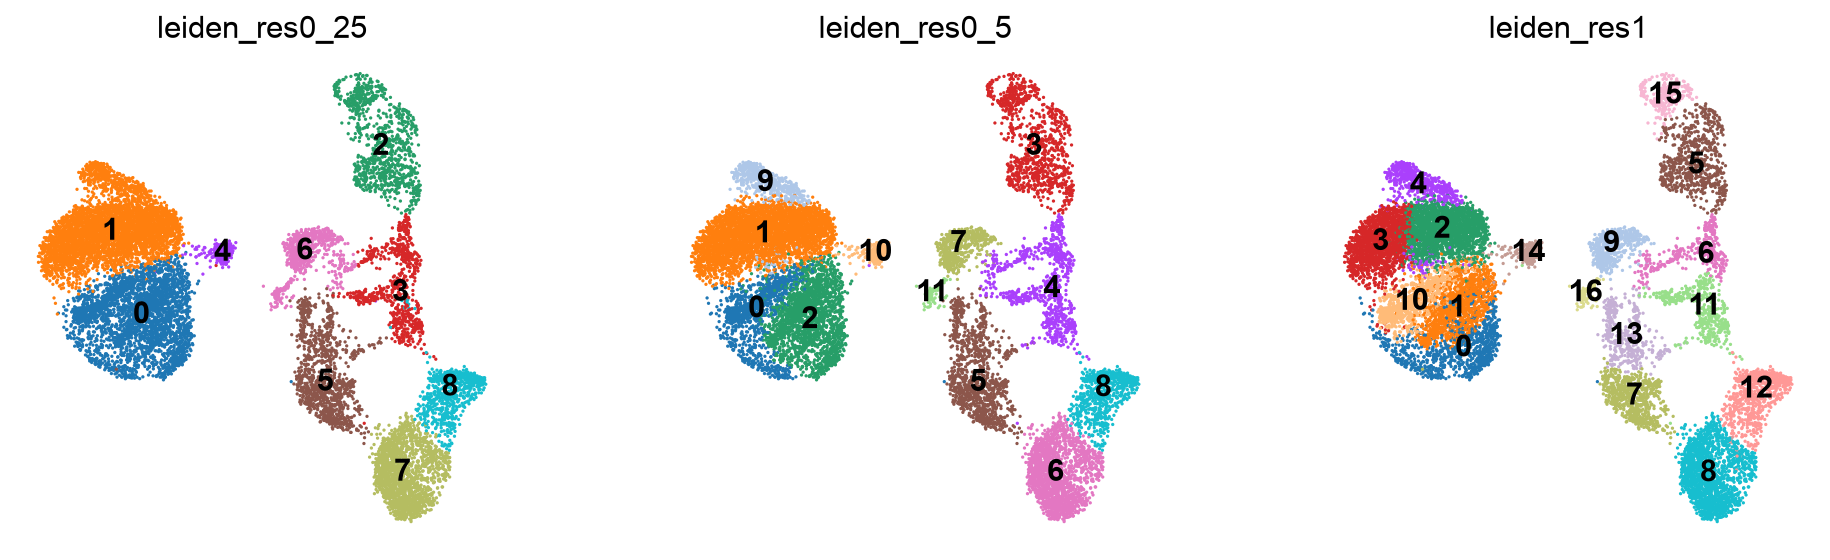

In [11]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

In [12]:
from pathlib import Path

output_dir = Path("../intermediate_data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "clustered.h5ad"

adata.write_h5ad(output_path, compression="gzip")
print(f"Saved anndata after clustering to: {output_path.resolve()}")

Saved anndata after clustering to: /Users/ankitmukherjee/Bioinformatics/single_cell_analysis/scverse/05_scRNA_analysis/intermediate_data/clustered.h5ad
